# Online Shopping Purchase Intention Prediction

## Project Objective
The main objective of this project is to analyze
online shopping customer behaviour and predict
whether a customer will make a purchase or not
using Machine Learning.

## Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Machine Learning

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [3]:
df = pd.read_csv("online_shoppers_intention.csv")

df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
df.tail()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
12325,3,145.0,0,0.0,53,1783.791667,0.007143,0.029031,12.241717,0.0,Dec,4,6,1,1,Returning_Visitor,True,False
12326,0,0.0,0,0.0,5,465.750000,0.000000,0.021333,0.000000,0.0,Nov,3,2,1,8,Returning_Visitor,True,False
12327,0,0.0,0,0.0,6,184.250000,0.083333,0.086667,0.000000,0.0,Nov,3,2,1,13,Returning_Visitor,True,False
12328,4,75.0,0,0.0,15,346.000000,0.000000,0.021053,0.000000,0.0,Nov,2,2,3,11,Returning_Visitor,False,False
12329,0,0.0,0,0.0,3,21.250000,0.000000,0.066667,0.000000,0.0,Nov,3,2,1,2,New_Visitor,True,False


In [5]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Total Rows: 12330
Total Columns: 18


In [6]:
print("Dataset Columns:\n")

for col in df.columns:
    print(col)

Dataset Columns:

Administrative
Administrative_Duration
Informational
Informational_Duration
ProductRelated
ProductRelated_Duration
BounceRates
ExitRates
PageValues
SpecialDay
Month
OperatingSystems
Browser
Region
TrafficType
VisitorType
Weekend
Revenue


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [8]:
df.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [9]:
df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [10]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 125


In [11]:
print(df['Revenue'].value_counts())

Revenue
False    10422
True      1908
Name: count, dtype: int64


In [12]:
print("\nPurchase Percentage:")
print(df['Revenue'].value_counts(normalize=True) * 100)


Purchase Percentage:
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


**Data cleaning**

In [13]:
df = df.drop_duplicates()

print("Dataset Shape After Removing Duplicates:", df.shape)

Dataset Shape After Removing Duplicates: (12205, 18)


In [14]:
print("Remaining Duplicate Rows:", df.duplicated().sum())

Remaining Duplicate Rows: 0


In [15]:
print("Missing Values in Each Column:\n")
print(df.isnull().sum())

Missing Values in Each Column:

Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64


In [16]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


In [17]:
print(df['Month'].unique())

['Feb' 'Mar' 'May' 'Oct' 'June' 'Jul' 'Aug' 'Nov' 'Sep' 'Dec']


In [18]:
print(df['VisitorType'].unique())

['Returning_Visitor' 'New_Visitor' 'Other']


In [19]:
numerical_cols = df.select_dtypes(include=np.number).columns

categorical_cols = df.select_dtypes(include=['object', 'bool']).columns

print("Numerical Columns:")
print(list(numerical_cols))

print("\nCategorical Columns:")
print(list(categorical_cols))

Numerical Columns:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Categorical Columns:
['Month', 'VisitorType', 'Weekend', 'Revenue']


**data visualization**

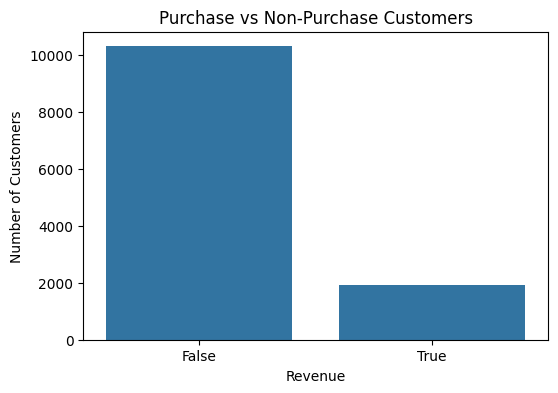

In [20]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Revenue')

plt.title("Purchase vs Non-Purchase Customers")
plt.xlabel("Revenue")
plt.ylabel("Number of Customers")

plt.show()

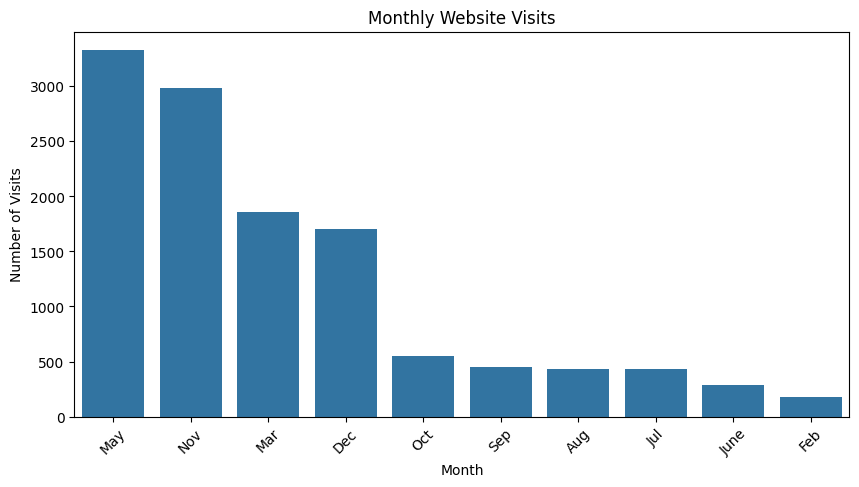

In [21]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='Month',
              order=df['Month'].value_counts().index)

plt.title("Monthly Website Visits")
plt.xlabel("Month")
plt.ylabel("Number of Visits")

plt.xticks(rotation=45)
plt.show()

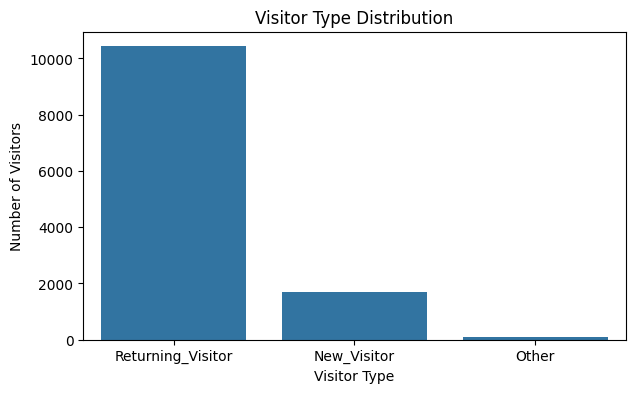

In [22]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x='VisitorType')

plt.title("Visitor Type Distribution")
plt.xlabel("Visitor Type")
plt.ylabel("Number of Visitors")

plt.show()

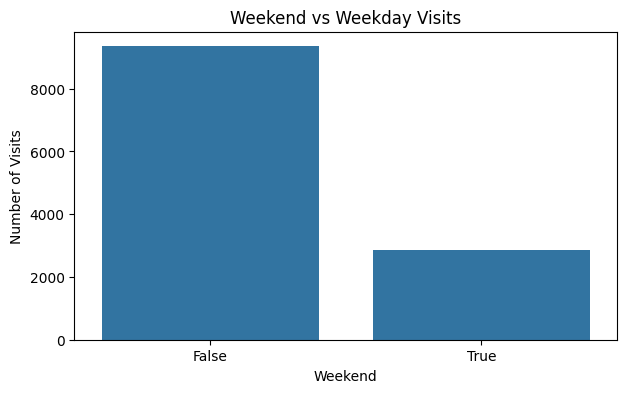

In [23]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x='Weekend')

plt.title("Weekend vs Weekday Visits")
plt.xlabel("Weekend")
plt.ylabel("Number of Visits")

plt.show()

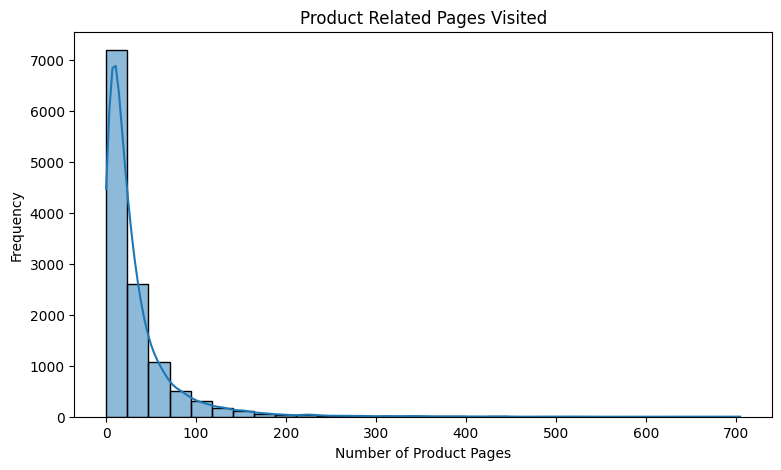

In [24]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='ProductRelated', bins=30, kde=True)

plt.title("Product Related Pages Visited")
plt.xlabel("Number of Product Pages")
plt.ylabel("Frequency")

plt.show()

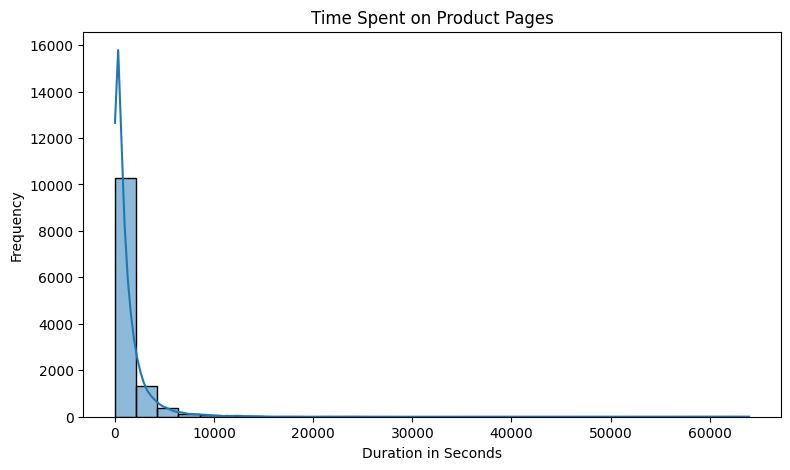

In [25]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='ProductRelated_Duration',
             bins=30, kde=True)

plt.title("Time Spent on Product Pages")
plt.xlabel("Duration in Seconds")
plt.ylabel("Frequency")

plt.show()

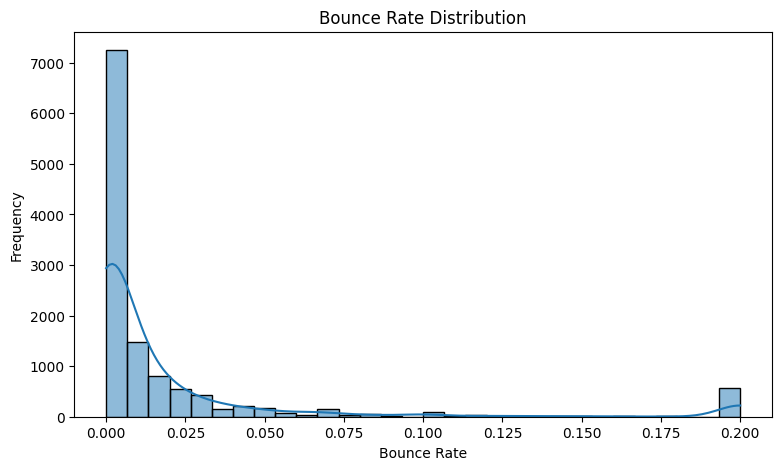

In [26]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='BounceRates', bins=30, kde=True)

plt.title("Bounce Rate Distribution")
plt.xlabel("Bounce Rate")
plt.ylabel("Frequency")

plt.show()

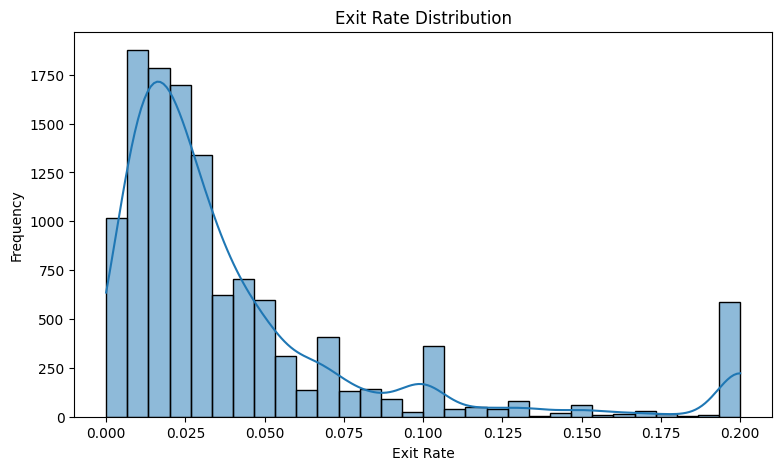

In [27]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='ExitRates', bins=30, kde=True)

plt.title("Exit Rate Distribution")
plt.xlabel("Exit Rate")
plt.ylabel("Frequency")

plt.show()

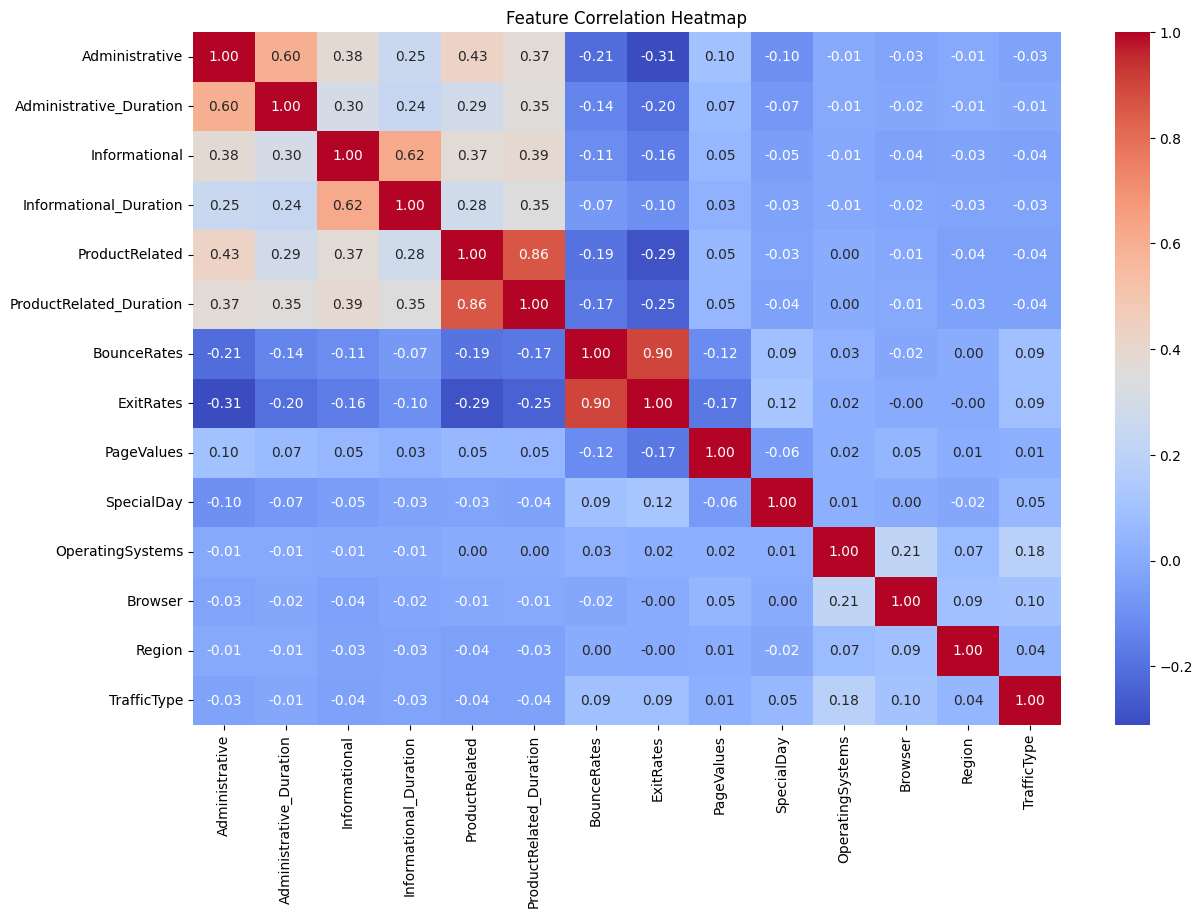

In [28]:
plt.figure(figsize=(14, 9))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm',
            fmt='.2f')

plt.title("Feature Correlation Heatmap")

plt.show()

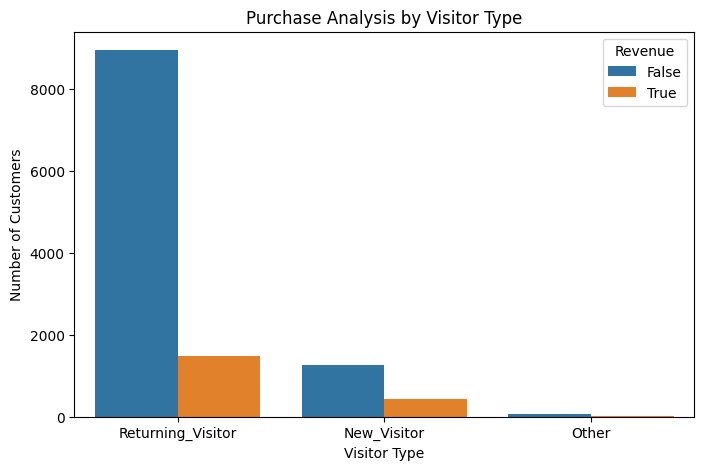

In [29]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='VisitorType', hue='Revenue')

plt.title("Purchase Analysis by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Number of Customers")

plt.show()

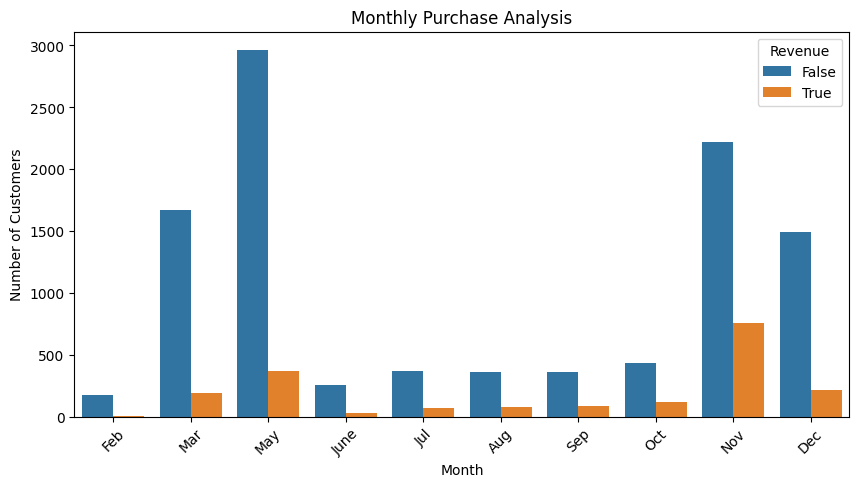

In [30]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='Month', hue='Revenue',
              order=['Feb', 'Mar', 'May', 'June',
                     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

plt.title("Monthly Purchase Analysis")
plt.xlabel("Month")
plt.ylabel("Number of Customers")

plt.xticks(rotation=45)
plt.show()

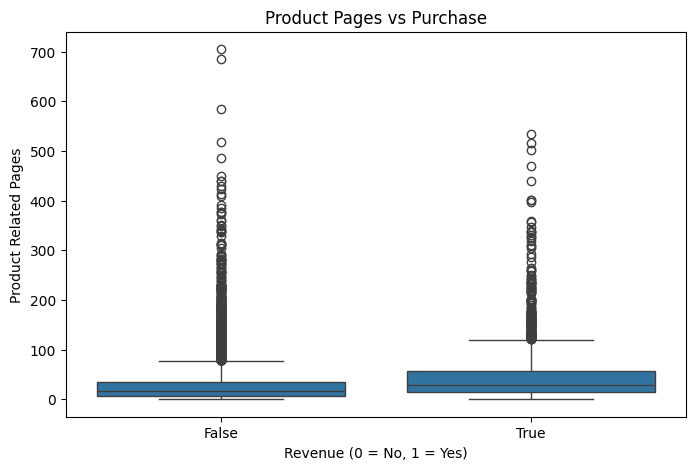

In [31]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Revenue', y='ProductRelated')

plt.title("Product Pages vs Purchase")
plt.xlabel("Revenue (0 = No, 1 = Yes)")
plt.ylabel("Product Related Pages")

plt.show()

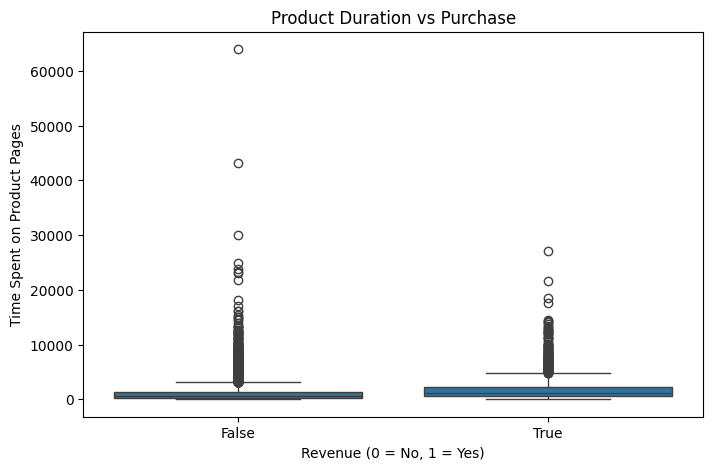

In [32]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='Revenue', y='ProductRelated_Duration')

plt.title("Product Duration vs Purchase")
plt.xlabel("Revenue (0 = No, 1 = Yes)")
plt.ylabel("Time Spent on Product Pages")

plt.show()

In [33]:
df['Revenue'] = df['Revenue'].astype(int)

print(df['Revenue'].value_counts())

Revenue
0    10297
1     1908
Name: count, dtype: int64


**Categorical columns encoding**

In [34]:
df = pd.get_dummies(
    df,
    columns=['Month', 'VisitorType'],
    drop_first=True,
    dtype=int
)

print("Encoding Completed!")
print("New Dataset Shape:", df.shape)

Encoding Completed!
New Dataset Shape: (12205, 27)


**Model Training**

In [35]:
X = df.drop('Revenue', axis=1)

y = df['Revenue']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (12205, 26)
Target Shape: (12205,)


In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (9764, 26)
Testing Data: (2441, 26)


In [37]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced'
)

lr_model.fit(X_train, y_train)

print("Logistic Regression Model Trained!")

Logistic Regression Model Trained!


In [38]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained!")

Random Forest Model Trained!


**Model Evaluation**

In [39]:
from sklearn.metrics import accuracy_score, classification_report

lr_pred = lr_model.predict(X_test)
rf_pred = rf_model.predict(X_test)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_pred))

print("\nRandom Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_pred))

Logistic Regression Accuracy: 0.8582548136009832

Random Forest Accuracy: 0.902498975829578

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      2059
           1       0.75      0.57      0.64       382

    accuracy                           0.90      2441
   macro avg       0.84      0.77      0.79      2441
weighted avg       0.90      0.90      0.90      2441



**Final Prediction**

In [40]:
best_model = rf_model

sample_customer = X_test.iloc[[0]]

prediction = best_model.predict(sample_customer)

if prediction[0] == 1:
    print("Customer Will Purchase!")
else:
    print("Customer Will Not Purchase!")

Customer Will Not Purchase!


**Model Deployment**

In [41]:
import pickle

# Save the trained Random Forest model
with open('purchase_prediction_model.pkl', 'wb') as file:
    pickle.dump(best_model, file)

print("Model Saved Successfully!")


Model Saved Successfully!


In [42]:

import os

print(os.path.exists('purchase_prediction_model.pkl'))


True
